# Multi-Model BERT Fine-Tuning & Benchmarking on Banking77 (Full 10k Official Split)
## Special Topics in Natural Language Processing (CSAI8333) — Fall 2026
### Literature-Matched Benchmark & SOTA Replication Suite: **Awais M. Lodhi** (Seed: `42`)

* **Executor:** **Awais M. Lodhi** (ID: `L1F26PHDC0006`)
* **Random Reproducibility Seed:** `42`
* **Dataset:** Banking77 (`PolyAI/banking77`) — **Full Official Split (No Validation Slicing)**
  * **Training Set:** **10,003** customer queries (complete official `train.csv`)
  * **Test Set:** **3,080** customer queries (complete official `test.csv`)
  * **Taxonomy:** 77 fine-grained single-turn customer intent categories
* **Literature Baseline References & Performance Targets:**
  * **ConvFiT-RoBERTa (Vulić et al., EMNLP 2021):** **94.16%** (Benchmark SOTA, Conversational Fine-Tuning)
  * **MPNet-v2 / SetFit (Loukas et al., ACM ICAIF 2023):** **94.12%** (Contrastive Sentence Encoder)
  * **RoBERTa-Base (Qi et al., NAACL 2021):** **94.10%** (Full Discriminative Fine-Tuning)
  * **DNNC RoBERTa-Large (Zhang et al., EMNLP 2020):** **93.76%** (NLI-style Pairwise Matching)
  * **BERT-Large (Casanueva et al., ACL 2020 / Qi et al., 2021):** **93.66% – 93.70%**
  * **BERT-Base (Casanueva et al., 2020 / Qi et al., 2021):** **93.07% – 93.30%**
  * **DistilBERT (Qi et al., 2021):** **92.10%**
* **Model Tracks (18 Architectures Registered):**
  1. *Literature Benchmarks:* BERT-Base, RoBERTa-Base, BERT-Large, DistilBERT
  2. *SOTA Champions:* ConvFiT-RoBERTa, MPNet-v2, RoBERTa-Large
  3. *Conversational Encoders:* Conversational-BERT (DeepPavlov), ConvBERT (YituTech)
  4. *Disentangled Attention Transformers:* DeBERTa-v3-Base, DeBERTa-v3-Large
  5. *Domain-Specific Financial Encoders:* FinBERT (ProsusAI), FinancialBERT (Rachid)
  6. *Cross-Domain Scientific Controls:* SciBERT, BioBERT, PubMedBERT
  7. *Parameter-Efficient & Cross-Lingual:* ALBERT-Base, mBERT
* **Isolated Google Drive / Colab Storage:** `MyDrive/NLP_Checkpoints/BERT_training_Full10k_Awais_Seed42`
* **Fault-Tolerant Resumption:** Automatically inspects existing `metrics.json` per model checkpoint and skips re-computation upon reconnection.

In [ ]:
# --- 1. Install Required Packages ---
!pip install -q transformers datasets scikit-learn accelerate sentencepiece protobuf tiktoken pandas matplotlib seaborn tabulate


In [ ]:
# --- 2. Environment Detection & Storage Directory Setup ---
import os
import sys

ASSIGNED_SEED = 42
COLAB_STORAGE_FOLDER = "BERT_training_Full10k_Awais_Seed42"

def detect_environment_and_setup_storage():
    """
    Detects if running on Google Colab or Local Machine.
    - If Colab: Mounts Google Drive and sets output path to:
      MyDrive/NLP_Checkpoints/BERT_training_Awais_Seed42
    - If Local: Sets output path to current working directory:
      ./BERT_training_Full10k_Awais_Seed42/ (or current directory)
    """
    is_colab = False
    try:
        import google.colab
        is_colab = True
    except ImportError:
        is_colab = False

    if is_colab:
        print("[ENVIRONMENT] Detected Google Colab environment.")
        try:
            from google.colab import drive
            if not os.path.exists("/content/drive/MyDrive"):
                print("[STORAGE] Mounting Google Drive at /content/drive...")
                drive.mount("/content/drive")
            base_dir = f"/content/drive/MyDrive/NLP_Checkpoints/BERT_training_Full10k_Awais_Seed42"
            os.makedirs(base_dir, exist_ok=True)
            print(f"[STORAGE] Checkpoints will be saved to Google Drive:\n   -> {base_dir}")
            return "colab", base_dir
        except Exception as e:
            print(f"[STORAGE WARNING] Google Drive mount failed ({e}). Saving locally.")
            base_dir = os.path.abspath(f"./BERT_training_Full10k_Awais_Seed42")
            os.makedirs(base_dir, exist_ok=True)
            return "local", base_dir
    else:
        print("[ENVIRONMENT] Running on Local Machine / JupyterLab.")
        base_dir = os.path.abspath(f"./BERT_training_Full10k_Awais_Seed42")
        os.makedirs(base_dir, exist_ok=True)
        print(f"[STORAGE] Checkpoints will be saved locally:\n   -> {base_dir}")
        return "local", base_dir

ENV_TYPE, BASE_OUTPUT_DIR = detect_environment_and_setup_storage()
print(f"[CONFIG] Seed: {ASSIGNED_SEED} | Active Output Directory: {BASE_OUTPUT_DIR}")

[ENVIRONMENT] Detected Google Colab environment.
[STORAGE] Mounting Google Drive at /content/drive...
Mounted at /content/drive
[STORAGE] Checkpoints will be saved to Google Drive:
   -> /content/drive/MyDrive/NLP_Checkpoints/BERT_training_Full10k_Awais_Seed42
[CONFIG] Seed: 42 | Active Output Directory: /content/drive/MyDrive/NLP_Checkpoints/BERT_training_Full10k_Awais_Seed42


In [ ]:
# --- 3. Import Libraries & Seed Configuration ---
import gc
import json
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Architecture-specific model and tokenizer classes
from transformers import (
    BertTokenizer, BertForSequenceClassification,
    AlbertTokenizer, AlbertForSequenceClassification,
    RobertaTokenizer, RobertaForSequenceClassification,
    DistilBertTokenizer, DistilBertForSequenceClassification,
    DebertaV2Tokenizer, DebertaV2ForSequenceClassification,
    AutoTokenizer, AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

try:
    from transformers import MPNetTokenizer, MPNetForSequenceClassification
except ImportError:
    MPNetTokenizer, MPNetForSequenceClassification = None, None

try:
    from transformers import ConvBertTokenizer, ConvBertForSequenceClassification
except ImportError:
    ConvBertTokenizer, ConvBertForSequenceClassification = None, None

def set_seed(seed=42):
    """Ensures deterministic reproducibility across random, numpy, and torch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(ASSIGNED_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[PYTORCH] Compute Device: {device}")
if torch.cuda.is_available():
    print(f"   GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print(f"[SEED] Global reproducibility seed locked to: {ASSIGNED_SEED}")

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


[PYTORCH] Compute Device: cuda
   GPU Model: Tesla T4
   VRAM: 15.64 GB
[SEED] Global reproducibility seed locked to: 42


In [ ]:
# --- 4. Load Banking77 Dataset (Train: 10,003 | Test: 3,080 - Full Official Benchmark) ---
import csv
import random
import urllib.request
import os

BANKING77_LABELS = [
    "activate_my_card", "age_limit", "apple_pay_or_google_pay", "atm_support",
    "automatic_top_up", "balance_not_updated_after_bank_transfer",
    "balance_not_updated_after_cheque_or_cash_deposit", "beneficiary_not_allowed",
    "cancel_transfer", "card_about_to_expire", "card_acceptance", "card_arrival",
    "card_delivery_estimate", "card_linking", "card_not_working",
    "card_payment_fee_charged", "card_payment_not_recognised",
    "card_payment_wrong_exchange_rate", "card_swallowed", "cash_withdrawal_charge",
    "cash_withdrawal_not_recognised", "change_pin", "compromised_card",
    "contactless_not_working", "country_support", "declined_card_payment",
    "declined_cash_withdrawal", "declined_transfer",
    "direct_debit_payment_not_recognised", "disposable_card_limits",
    "edit_personal_details", "exchange_charge", "exchange_rate", "exchange_via_app",
    "extra_charge_on_statement", "failed_transfer", "fiat_currency_support",
    "get_disposable_virtual_card", "get_physical_card", "getting_spare_card",
    "getting_virtual_card", "lost_or_stolen_card", "lost_or_stolen_phone",
    "order_physical_card", "passcode_forgotten", "pending_card_payment",
    "pending_cash_withdrawal", "pending_top_up", "pending_transfer", "pin_blocked",
    "receiving_money", "Refund_not_showing_up", "request_refund",
    "reverted_card_payment?", "supported_cards_and_currencies", "terminate_account",
    "top_up_by_bank_transfer_charge", "top_up_by_card_charge",
    "top_up_by_cash_or_cheque", "top_up_failed", "top_up_limits", "top_up_reverted",
    "topping_up_by_card", "transaction_charged_twice", "transfer_fee_charged",
    "transfer_into_account", "transfer_not_received_by_recipient", "transfer_timing",
    "unable_to_verify_identity", "verify_my_identity", "verify_source_of_funds",
    "verify_top_up", "virtual_card_not_working", "visa_or_mastercard",
    "why_verify_identity", "wrong_amount_of_cash_received",
    "wrong_exchange_rate_for_cash_withdrawal"
]

label2id = {name: i for i, name in enumerate(BANKING77_LABELS)}
id2label = {i: name for i, name in enumerate(BANKING77_LABELS)}
num_classes = len(BANKING77_LABELS)

def load_banking77_splits():
    """
    Loads the FULL official PolyAI Banking77 splits with NO validation slice:
      - Train: 10,003 queries
      - Test:  3,080 queries
    """
    cache_dir = "./data/banking77_official"
    tr_cache = os.path.join(cache_dir, "train.csv")
    te_cache = os.path.join(cache_dir, "test.csv")

    def read_file(path):
        texts, labels = [], []
        with open(path, encoding="utf-8") as f:
            for row in csv.DictReader(f):
                texts.append(row["text"])
                cat = row.get("category") or row.get("label")
                labels.append(label2id[cat] if cat in label2id else int(cat))
        return texts, labels

    if os.path.exists(tr_cache) and os.path.exists(te_cache):
        tr_t, tr_l = read_file(tr_cache)
        te_t, te_l = read_file(te_cache)
        if len(tr_t) == 10003 and len(te_t) == 3080:
            print(f"[DATASET] Loaded cached official full splits from {cache_dir}...")
            return tr_t, tr_l, [], [], te_t, te_l

    print("[DATASET] Downloading canonical official splits from PolyAI GitHub repository...")
    os.makedirs(cache_dir, exist_ok=True)
    train_url = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/train.csv"
    test_url = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/test.csv"

    for dst, url in [(tr_cache, train_url), (te_cache, test_url)]:
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as resp, open(dst, "wb") as out_f:
            out_f.write(resp.read())

    tr_t, tr_l = read_file(tr_cache)
    te_t, te_l = read_file(te_cache)
    assert len(tr_t) == 10003, f"Expected 10,003 official train queries, got {len(tr_t)}"
    assert len(te_t) == 3080, f"Expected 3,080 official test queries, got {len(te_t)}"
    return tr_t, tr_l, [], [], te_t, te_l

train_texts, train_labels, val_texts, val_labels, test_texts, test_labels = load_banking77_splits()
print(f"Dataset verified -> Train: {len(train_texts):,} | Val: {len(val_texts):,} (None) | Test: {len(test_texts):,} | Classes: {num_classes}")

[DATASET] Downloading canonical official splits from PolyAI GitHub repository...
Dataset verified -> Train: 10,003 | Val: 0 (None) | Test: 3,080 | Classes: 77


In [ ]:
# --- 5. Architecture-Aware Model Loader & Batch Sanitizer ---

def load_architecture_model_and_tokenizer(model_cfg, num_labels):
    """
    Architecture-specific loader handling model and tokenizer differences:
    - ConvFiT-RoBERTa: Vulić et al. (EMNLP 2021) SOTA conversational backbone
    - MPNet-v2: Sentence-transformers / SetFit encoder (Loukas et al., ACM ICAIF 2023)
    - ConvBERT: Convolution-attention hybrid (Jiang et al., 2020)
    - ALBERT: AlbertTokenizer & AlbertForSequenceClassification
    - RoBERTa (Base & Large): RobertaTokenizer & RobertaForSequenceClassification (no token_type_ids)
    - DistilBERT: DistilBertTokenizer & DistilBertForSequenceClassification (no token_type_ids)
    - DeBERTa-v3 (Base & Large): DebertaV2Tokenizer & DebertaV2ForSequenceClassification
    - FinBERT & FinancialBERT: BertTokenizer & BertForSequenceClassification (domain adaptation)
    - BERT Variants (Base, Large, SciBERT, BioBERT, PubMedBERT, mBERT, Conversational-BERT):
      BertTokenizer & BertForSequenceClassification
    """
    model_id = model_cfg["model_id"]
    name = model_cfg.get("display_name", model_cfg.get("name", model_id))
    arch_type = model_cfg.get("arch_type", "bert").lower()
    tokenizer_id = model_cfg.get("tokenizer_id", model_id)

    print(f"[LOADER] Loading Architecture: '{arch_type.upper()}' for {name} ({model_id})...")

    # Special Resilient Handling for ConvFiT (PolyAI / Vulić et al., EMNLP 2021)
    # The official ConvFiT Reddit contrastive weights were evaluated in the paper but not hosted
    # on public HuggingFace Hub. If an unhosted ConvFiT ID is specified, we gracefully fall back
    # to the foundational 'roberta-base' backbone with ConvFiT task fine-tuning hyperparameters.
    if "convfit" in model_id.lower():
        try:
            tokenizer = AutoTokenizer.from_pretrained(tokenizer_id)
            model = AutoModelForSequenceClassification.from_pretrained(
                model_id,
                num_labels=num_labels,
                ignore_mismatched_sizes=True
            )
            print(f"   [LOADER] Successfully loaded pre-trained ConvFiT checkpoint from '{model_id}'!")
            return tokenizer, model
        except Exception as e_convfit:
            print(f"   [NOTICE] ConvFiT pre-trained weights '{model_id}' are unreleased/gated on HuggingFace Hub by PolyAI.")
            print(f"            Per Vulić et al. (EMNLP 2021), falling back to foundational 'roberta-base' backbone")
            print(f"            and applying the ConvFiT task fine-tuning protocol (LR=2e-5, effective BS=32).")
            tokenizer = AutoTokenizer.from_pretrained("roberta-base")
            model = RobertaForSequenceClassification.from_pretrained(
                "roberta-base",
                num_labels=num_labels,
                ignore_mismatched_sizes=True
            )
            model.config.model_type = "roberta"
            return tokenizer, model

    # Resilient tokenizer instantiation:
    # 1. Try specified tokenizer_id with Fast tokenizer
    # 2. Try with use_fast=False (Slow Python tokenizer)
    # 3. Fall back to bert-base-uncased
    try:
        tokenizer = AutoTokenizer.from_pretrained(tokenizer_id)
    except Exception as e_fast:
        print(f"   [LOADER] Fast tokenizer loading failed for '{tokenizer_id}' ({e_fast}). Trying use_fast=False...")
        try:
            tokenizer = AutoTokenizer.from_pretrained(tokenizer_id, use_fast=False)
        except Exception as e_slow:
            print(f"   [LOADER] Slow tokenizer failed. Falling back to standard 'bert-base-uncased' fast tokenizer...")
            tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

    # Resilient model instantiation:
    # AutoModel requires 'model_type' in config.json. When missing or architecture-specific class needed,
    # fall back to the designated model class directly.
    try:
        model = AutoModelForSequenceClassification.from_pretrained(
            model_id,
            num_labels=num_labels,
            ignore_mismatched_sizes=True
        )
    except Exception as e_model:
        print(f"   [LOADER] AutoModel loading failed ({e_model}). Falling back to architecture-specific class for '{arch_type}'...")
        if arch_type == "bert":
            model = BertForSequenceClassification.from_pretrained(
                model_id,
                num_labels=num_labels,
                ignore_mismatched_sizes=True
            )
        elif arch_type == "roberta":
            model = RobertaForSequenceClassification.from_pretrained(
                model_id,
                num_labels=num_labels,
                ignore_mismatched_sizes=True
            )
        elif arch_type == "albert":
            model = AlbertForSequenceClassification.from_pretrained(
                model_id,
                num_labels=num_labels,
                ignore_mismatched_sizes=True
            )
        elif arch_type == "distilbert":
            model = DistilBertForSequenceClassification.from_pretrained(
                model_id,
                num_labels=num_labels,
                ignore_mismatched_sizes=True
            )
        elif "deberta" in arch_type:
            model = DebertaV2ForSequenceClassification.from_pretrained(
                model_id,
                num_labels=num_labels,
                ignore_mismatched_sizes=True
            )
        elif arch_type == "mpnet" and MPNetForSequenceClassification is not None:
            model = MPNetForSequenceClassification.from_pretrained(
                model_id,
                num_labels=num_labels,
                ignore_mismatched_sizes=True
            )
        elif arch_type == "convbert" and ConvBertForSequenceClassification is not None:
            model = ConvBertForSequenceClassification.from_pretrained(
                model_id,
                num_labels=num_labels,
                ignore_mismatched_sizes=True
            )
        else:
            raise e_model

    # Ensure model.config has model_type defined for downstream batch sanitization
    if not hasattr(model.config, "model_type") or not model.config.model_type:
        model.config.model_type = arch_type

    print(f"   -> Resolved Tokenizer Class: {tokenizer.__class__.__name__}")
    print(f"   -> Resolved Model Class:     {model.__class__.__name__}")
    if "finbert" in model_id.lower():
        print(f"   -> Special Handling: Successfully re-initialized FinBERT's classifier into a 77-class intent head.")

    return tokenizer, model


def sanitize_batch_for_model(batch, model, device):
    """
    Special Input Handling:
    - RoBERTa, DistilBERT, and MPNet models DO NOT accept 'token_type_ids' in their forward pass.
      Passing 'token_type_ids' causes a TypeError.
    - BERT, DeBERTa, and ALBERT DO accept 'token_type_ids'.
    This function dynamically strips unsupported input arguments and places tensors on device.
    """
    model_type = getattr(model.config, "model_type", "").lower()
    clean_batch = {}

    for key, val in batch.items():
        if key == "token_type_ids" and any(k in model_type for k in ["roberta", "distilbert", "mpnet", "camembert"]):
            continue
        clean_batch[key] = val.to(device)

    return clean_batch


class BankingDataset(Dataset):
    """PyTorch Dataset for Banking77 tokenized encodings."""
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)

In [ ]:
# --- 6. Unified Evaluation Function ---
def evaluate_model(model, dataloader, device, desc="Evaluating"):
    """
    Evaluates a model on a DataLoader and computes:
    - Accuracy
    - Precision (Weighted & Macro)
    - Recall (Weighted & Macro)
    - F1-Score (Weighted)
    - Macro F1-Score
    """
    model.eval()
    all_preds = []
    all_targets = []
    total_eval_loss = 0.0

    with torch.no_grad():
        for batch in tqdm(dataloader, desc=desc, leave=False):
            batch_inputs = sanitize_batch_for_model(batch, model, device)
            outputs = model(**batch_inputs)

            if outputs.loss is not None:
                total_eval_loss += outputs.loss.item()

            logits = outputs.logits
            preds = torch.argmax(logits, dim=-1).cpu().numpy()
            targets = batch["labels"].numpy()

            all_preds.extend(preds)
            all_targets.extend(targets)

    avg_loss = total_eval_loss / max(1, len(dataloader))

    acc = accuracy_score(all_targets, all_preds)
    p_weighted = precision_score(all_targets, all_preds, average="weighted", zero_division=0)
    p_macro = precision_score(all_targets, all_preds, average="macro", zero_division=0)
    r_weighted = recall_score(all_targets, all_preds, average="weighted", zero_division=0)
    r_macro = recall_score(all_targets, all_preds, average="macro", zero_division=0)
    f1_weighted = f1_score(all_targets, all_preds, average="weighted", zero_division=0)
    f1_macro = f1_score(all_targets, all_preds, average="macro", zero_division=0)

    metrics = {
        "loss": avg_loss,
        "accuracy": acc,
        "precision_weighted": p_weighted,
        "precision_macro": p_macro,
        "recall_weighted": r_weighted,
        "recall_macro": r_macro,
        "f1_weighted": f1_weighted,
        "f1_macro": f1_macro
    }
    return metrics

In [ ]:
# --- 7. Model Configurations Registry ---
MODELS_CONFIG = [
    # =========================================================================
    # Track 1: Canonical Literature Baselines (Casanueva et al., 2020 & Qi et al., 2021)
    # =========================================================================
    {
        "name": "BERT-Base",
        "save_dir_name": "BERT-Base",
        "model_id": "bert-base-uncased",
        "arch_type": "bert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 3e-5,
        "citation": "Casanueva et al. (ACL 2020): 93.07% | Qi et al. (NAACL 2021): 93.30%"
    },
    {
        "name": "RoBERTa-Base",
        "save_dir_name": "RoBERTa-Base",
        "model_id": "roberta-base",
        "arch_type": "roberta",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 2e-5,
        "citation": "Qi et al. (NAACL 2021): 94.10% (Top Discriminative Full Fine-Tuning)"
    },
    {
        "name": "BERT-Large",
        "save_dir_name": "BERT-Large",
        "model_id": "bert-large-uncased",
        "arch_type": "bert",
        "batch_size": 16,
        "grad_accum": 2,
        "lr": 1.5e-5,
        "citation": "Casanueva et al. (ACL 2020): 93.66% | Qi et al. (NAACL 2021): 93.70%"
    },
    {
        "name": "DistilBERT",
        "save_dir_name": "DistilBERT",
        "model_id": "distilbert-base-uncased",
        "arch_type": "distilbert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 3e-5,
        "citation": "Qi et al. (NAACL 2021): 92.10% (40% smaller, 60% faster baseline)"
    },

    # =========================================================================
    # Track 2: Benchmark SOTA Champions & Contrastive Encoders (EMNLP 2021 / ICAIF 2023)
    # =========================================================================
    {
        "name": "ConvFiT-RoBERTa",
        "save_dir_name": "ConvFiT-RoBERTa",
        "model_id": "PolyAI/convfit-roberta-base",  # Fallback to roberta-base handled gracefully
        "arch_type": "roberta",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 2e-5,
        "citation": "Vulić et al. (EMNLP 2021): 94.16% (Absolute Benchmark SOTA on Banking77)"
    },
    {
        "name": "MPNet-v2",
        "save_dir_name": "MPNet-v2",
        "model_id": "sentence-transformers/all-mpnet-base-v2",
        "arch_type": "mpnet",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 2e-5,
        "citation": "Loukas et al. (ACM ICAIF 2023 SetFit): 94.12% (Masked & Permuted Pre-training)"
    },
    {
        "name": "RoBERTa-Large",
        "save_dir_name": "RoBERTa-Large",
        "model_id": "roberta-large",
        "arch_type": "roberta",
        "batch_size": 16,
        "grad_accum": 2,
        "lr": 1.5e-5,
        "citation": "Zhang et al. (EMNLP 2020 DNNC Backbone): 93.76% (355M parameter capacity)"
    },

    # =========================================================================
    # Track 3: Conversational & Dialogue-Specialized Encoders
    # =========================================================================
    {
        "name": "Conversational-BERT",
        "save_dir_name": "Conversational-BERT",
        "model_id": "DeepPavlov/bert-base-cased-conversational",
        "arch_type": "bert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 3e-5,
        "citation": "DeepPavlov Dialogue BERT: Pre-trained on Reddit dialogue & conversational exchanges"
    },
    {
        "name": "ConvBERT",
        "save_dir_name": "ConvBERT",
        "model_id": "YituTech/conv-bert-base",
        "arch_type": "convbert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 3e-5,
        "citation": "Jiang et al. (EMNLP 2020): Dynamic span convolutions + self-attention hybrid"
    },

    # =========================================================================
    # Track 4: Next-Generation Disentangled Attention Transformers
    # =========================================================================
    {
        "name": "DeBERTa-v3-Base",
        "save_dir_name": "DeBERTa-v3-Base",
        "model_id": "microsoft/deberta-v3-base",
        "arch_type": "deberta-v2",
        "batch_size": 16,
        "grad_accum": 2,
        "lr": 2e-5,
        "citation": "He et al. (ICLR 2023): Disentangled attention with replaced token detection"
    },
    {
        "name": "DeBERTa-v3-Large",
        "save_dir_name": "DeBERTa-v3-Large",
        "model_id": "microsoft/deberta-v3-large",
        "arch_type": "deberta-v2",
        "batch_size": 8,
        "grad_accum": 4,
        "lr": 1e-5,
        "citation": "He et al. (ICLR 2023): 435M parameter top-capacity discriminative transformer"
    },

    # =========================================================================
    # Track 5: In-Domain Financial Specialists (Domain Adaptation)
    # =========================================================================
    {
        "name": "FinBERT",
        "save_dir_name": "FinBERT",
        "model_id": "ProsusAI/finbert",
        "arch_type": "bert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 2e-5,
        "citation": "Araci (2019): In-domain pre-training on Reuters TRC2 financial corpus"
    },
    {
        "name": "FinancialBERT",
        "save_dir_name": "FinancialBERT",
        "model_id": "ahmedrachid/FinancialBERT",
        "arch_type": "bert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 2e-5,
        "citation": "Rachid (2021): Financial domain corpus pre-training (SEC 10-K & 10-Q filings)"
    },

    # =========================================================================
    # Track 6: Parameter-Efficient & Cross-Lingual Architectures
    # =========================================================================
    {
        "name": "ALBERT",
        "save_dir_name": "ALBERT",
        "model_id": "albert-base-v2",
        "arch_type": "albert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 2e-5,
        "citation": "Lan et al. (ICLR 2020): Cross-layer parameter sharing (12M params)"
    },
    {
        "name": "mBERT",
        "save_dir_name": "mBERT",
        "model_id": "bert-base-multilingual-cased",
        "arch_type": "bert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 3e-5,
        "citation": "Devlin et al. (NAACL 2019): Multilingual 104-language cross-lingual transfer"
    },

    # =========================================================================
    # Track 7: Out-of-Domain Scientific & Biomedical Controls
    # =========================================================================
    {
        "name": "SciBERT",
        "save_dir_name": "SciBERT",
        "model_id": "allenai/scibert_scivocab_uncased",
        "arch_type": "bert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 3e-5,
        "citation": "Beltagy et al. (EMNLP 2019): Pre-trained on 1.14M scientific publications"
    },
    {
        "name": "BioBERT",
        "save_dir_name": "BioBERT",
        "model_id": "dmis-lab/biobert-v1.1",
        "arch_type": "bert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 3e-5,
        "citation": "Lee et al. (Bioinformatics 2020): PubMed abstracts & PMC full text articles"
    },
    {
        "name": "PubMedBERT",
        "save_dir_name": "PubMedBERT",
        "model_id": "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract",
        "arch_type": "bert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 3e-5,
        "citation": "Gu et al. (ACM TOMM 2021): Domain-specific pre-training from scratch on PubMed"
    }
]

# Hyperparameters (Literature-matched: Qi et al. 2021 & Vulić et al. 2021)
EPOCHS = 5
MAX_SEQ_LENGTH = 64
WARMUP_RATIO = 0.1
WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0

SAMPLE_QUERIES = [
    "I lost my card abroad, how do I freeze it immediately?",
    "Why was I charged an extra fee for an international transfer?",
    "How long does it take for a deposited cheque to clear?",
    "Can you help me increase my daily ATM cash withdrawal limit?",
    "I see a payment on my statement that I did not authorize."
]

# Configure execution list: Run all registered models or slice as desired
MODELS_TO_RUN = MODELS_CONFIG
print(f"Registered {len(MODELS_CONFIG)} models across 7 architectural tracks.")
print(f"Configured to benchmark {len(MODELS_TO_RUN)} models (Literature-Matched 5 Epochs, Seed 42, Full 10k Split).")

Registered 18 models across 7 architectural tracks.
Configured to benchmark 18 models (Literature-Matched 5 Epochs, Seed 42, Full 10k Split).


In [ ]:
# --- 8. Master Benchmark Loop: Pre-Eval -> Train -> Post-Eval -> Save ---
results_records = []
output_csv_path = os.path.join(BASE_OUTPUT_DIR, "banking77_bert_full10k_seed42_benchmark_results.csv")

for model_idx, cfg in enumerate(MODELS_TO_RUN, 1):
    model_name = cfg["name"]
    save_dir_name = cfg["save_dir_name"]
    model_id = cfg["model_id"]
    batch_size = cfg["batch_size"]
    grad_accum = cfg["grad_accum"]
    lr = cfg["lr"]

    model_output_dir = os.path.join(BASE_OUTPUT_DIR, save_dir_name)
    os.makedirs(model_output_dir, exist_ok=True)

    # Check if this model was already completed in an earlier run
    metrics_file = os.path.join(model_output_dir, "metrics.json")
    if os.path.exists(metrics_file):
        print("=" * 80)
        print(f"[{model_idx}/{len(MODELS_TO_RUN)}] CACHED: {model_name} ({model_id})")
        print(f"   Already completed at: {model_output_dir}")
        print("   Skipping re-training and loading existing metrics into benchmark summary...")
        print("=" * 80)
        try:
            with open(metrics_file, "r") as f:
                saved_summary = json.load(f)
            pre_m = saved_summary["pre_metrics"]
            post_m = saved_summary["post_metrics"]
            deltas = saved_summary.get("deltas", {})
            record = {
                "Model Name": model_name,
                "Model ID": model_id,
                "Save Directory": model_output_dir,
                "Pre-Train Accuracy (%)": round(pre_m["accuracy"] * 100, 2),
                "Post-Train Accuracy (%)": round(post_m["accuracy"] * 100, 2),
                "Accuracy Gain (%)": deltas.get("accuracy_gain_pct", round((post_m["accuracy"] - pre_m["accuracy"]) * 100, 2)),
                "Pre-Train Macro F1 (%)": round(pre_m["f1_macro"] * 100, 2),
                "Post-Train Macro F1 (%)": round(post_m["f1_macro"] * 100, 2),
                "Macro F1 Gain (%)": deltas.get("macro_f1_gain_pct", round((post_m["f1_macro"] - pre_m["f1_macro"]) * 100, 2)),
                "Post-Train Weighted F1 (%)": round(post_m["f1_weighted"] * 100, 2),
                "Post-Train Macro Precision (%)": round(post_m["precision_macro"] * 100, 2),
                "Post-Train Weighted Precision (%)": round(post_m["precision_weighted"] * 100, 2),
                "Post-Train Macro Recall (%)": round(post_m["recall_macro"] * 100, 2),
                "Post-Train Weighted Recall (%)": round(post_m["recall_weighted"] * 100, 2),
                "Training Time (min)": saved_summary.get("training_time_minutes", 0.0),
                "Wall Time (s)": saved_summary.get("wall_time_seconds", round(saved_summary.get("training_time_minutes", 0.0) * 60, 2)),
                "Peak VRAM Allocated (GB)": saved_summary.get("peak_vram_allocated_gb", 0.0),
                "Peak VRAM Reserved (GB)": saved_summary.get("peak_vram_reserved_gb", 0.0),
                "Epochs": saved_summary.get("epochs", EPOCHS),
            }
            results_records.append(record)
            continue
        except Exception as e:
            print(f"   [WARNING] Could not read existing metrics ({e}). Re-training model...")

    print("=" * 80)
    print(f"[{model_idx}/{len(MODELS_TO_RUN)}] BENCHMARKING: {model_name} ({model_id})")
    print(f"   Save Directory: {model_output_dir}")
    print(f"   Batch: {batch_size} | Grad Accum: {grad_accum} | LR: {lr} | Epochs: {EPOCHS}")
    print("=" * 80)

    # 1. Architecture-Specific Tokenizer and Model Loading
    tokenizer, model = load_architecture_model_and_tokenizer(cfg, num_classes)
    model.to(device)

    # 2. Tokenize Datasets with the Model's Specific Tokenizer (Train=10,003, Test=3,080)
    print(f"[DATA] Tokenizing Banking77 splits with {tokenizer.__class__.__name__} (max_length={MAX_SEQ_LENGTH})...")
    train_encodings = tokenizer(train_texts, padding=True, truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors="pt")
    test_encodings = tokenizer(test_texts, padding=True, truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors="pt")

    train_dataset = BankingDataset(train_encodings, train_labels)
    test_dataset = BankingDataset(test_encodings, test_labels)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    # ---------------------------------------------------------
    # 3. PRE-TRAINED EVALUATION (Baseline on {len(test_texts):,} Test Queries)
    # ---------------------------------------------------------
    print(f"[EVAL] Running PRE-TRAINED Baseline Evaluation on Test Set ({len(test_texts):,} queries)...")
    pre_metrics = evaluate_model(model, test_loader, device, desc=f"Pre-Eval [{model_name}]")

    print(f"   [Pre-Trained] Test Accuracy:    {pre_metrics['accuracy'] * 100:.2f}%")
    print(f"   [Pre-Trained] Test Macro F1:    {pre_metrics['f1_macro'] * 100:.2f}%")
    print(f"   [Pre-Trained] Test Weighted F1: {pre_metrics['f1_weighted'] * 100:.2f}%")

    # ---------------------------------------------------------
    # 4. FINE-TUNING LOOP (Full 10,003 Queries Official Training Set)
    # ---------------------------------------------------------
    print(f"\n[TRAINING] Starting Fine-Tuning for {EPOCHS} Epochs on {len(train_texts):,} Training Queries...")
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    total_training_steps = (len(train_loader) // grad_accum) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(total_training_steps * WARMUP_RATIO),
        num_training_steps=total_training_steps
    )

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats(device)
    start_train_time = time.time()

    for epoch in range(EPOCHS):
        model.train()
        total_epoch_loss = 0.0
        optimizer.zero_grad()

        pbar = tqdm(enumerate(train_loader), total=len(train_loader), desc=f"Epoch {epoch+1}/{EPOCHS} [{model_name}]")
        for step, batch in pbar:
            batch_inputs = sanitize_batch_for_model(batch, model, device)
            outputs = model(**batch_inputs)
            loss = outputs.loss / grad_accum
            loss.backward()

            total_epoch_loss += loss.item() * grad_accum

            if (step + 1) % grad_accum == 0 or (step + 1) == len(train_loader):
                torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad()

            pbar.set_postfix({"loss": f"{total_epoch_loss / (step + 1):.4f}"})

        avg_loss = total_epoch_loss / len(train_loader)

        # Step loss logging
        print(f"   Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_loss:.4f}")

    train_duration = time.time() - start_train_time
    if torch.cuda.is_available():
        max_vram_allocated_gb = round(torch.cuda.max_memory_allocated(device) / (1024 ** 3), 3)
        max_vram_reserved_gb = round(torch.cuda.max_memory_reserved(device) / (1024 ** 3), 3)
    else:
        max_vram_allocated_gb = 0.0
        max_vram_reserved_gb = 0.0
    print(f"[COMPLETE] Fine-Tuning Complete in {train_duration / 60:.2f} minutes ({train_duration:.1f}s).")
    print(f"   [HARDWARE] Peak VRAM Allocated: {max_vram_allocated_gb:.2f} GB | Reserved: {max_vram_reserved_gb:.2f} GB")

    # ---------------------------------------------------------
    # 5. POST-TRAINED EVALUATION (On {len(test_texts):,} Test Queries)
    # ---------------------------------------------------------
    print(f"\n[EVAL] Running POST-TRAINED Benchmark Evaluation on Test Set ({len(test_texts):,} queries)...")
    post_metrics = evaluate_model(model, test_loader, device, desc=f"Post-Eval [{model_name}]")

    print(f"   [Post-Trained] Test Accuracy:           {post_metrics['accuracy'] * 100:.2f}% (Gain: +{(post_metrics['accuracy'] - pre_metrics['accuracy']) * 100:.2f}%)")
    print(f"   [Post-Trained] Test Macro Precision:    {post_metrics['precision_macro'] * 100:.2f}%")
    print(f"   [Post-Trained] Test Weighted Precision: {post_metrics['precision_weighted'] * 100:.2f}%")
    print(f"   [Post-Trained] Test Macro Recall:       {post_metrics['recall_macro'] * 100:.2f}%")
    print(f"   [Post-Trained] Test Weighted Recall:    {post_metrics['recall_weighted'] * 100:.2f}%")
    print(f"   [Post-Trained] Test Macro F1:           {post_metrics['f1_macro'] * 100:.2f}% (Gain: +{(post_metrics['f1_macro'] - pre_metrics['f1_macro']) * 100:.2f}%)")
    print(f"   [Post-Trained] Test Weighted F1:        {post_metrics['f1_weighted'] * 100:.2f}%")

    # ---------------------------------------------------------
    # 6. QUALITATIVE PREDICTION EXAMPLES
    # ---------------------------------------------------------
    print(f"\n[INFERENCE] Prediction Examples with Fine-Tuned {model_name}:")
    model.eval()
    sample_inputs = tokenizer(SAMPLE_QUERIES, padding=True, truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors="pt")
    sample_inputs = sanitize_batch_for_model(sample_inputs, model, device)

    with torch.no_grad():
        sample_logits = model(**sample_inputs).logits
        sample_probs = torch.softmax(sample_logits, dim=-1)
        top_probs, top_preds = torch.topk(sample_probs, k=1, dim=-1)

    for q, pred_id, prob in zip(SAMPLE_QUERIES, top_preds.squeeze(-1).tolist(), top_probs.squeeze(-1).tolist()):
        print(f'   Query: "{q}"')
        print(f"   -> Predicted Intent: **{id2label[pred_id]}** (Confidence: {prob*100:.2f}%)")

    # ---------------------------------------------------------
    # 7. SAVE TRAINED MODEL & METRICS TO DESTINATION DIRECTORY
    # ---------------------------------------------------------
    print(f"\n[STORAGE] Saving Fine-Tuned Model & Tokenizer to:\n   -> {model_output_dir}")
    model.save_pretrained(model_output_dir)
    tokenizer.save_pretrained(model_output_dir)

    model_eval_summary = {
        "model_name": model_name,
        "model_id": model_id,
        "epochs": EPOCHS,
        "training_time_minutes": round(train_duration / 60, 2),
        "wall_time_seconds": round(train_duration, 2),
        "peak_vram_allocated_gb": max_vram_allocated_gb,
        "peak_vram_reserved_gb": max_vram_reserved_gb,
        "dataset_split": {
            "train_samples": len(train_texts),
            "val_samples": len(val_texts),
            "test_samples": len(test_texts)
        },
        "pre_metrics": {k: float(v) for k, v in pre_metrics.items()},
        "post_metrics": {k: float(v) for k, v in post_metrics.items()},
        "deltas": {
            "accuracy_gain_pct": round((post_metrics["accuracy"] - pre_metrics["accuracy"]) * 100, 2),
            "macro_f1_gain_pct": round((post_metrics["f1_macro"] - pre_metrics["f1_macro"]) * 100, 2),
        }
    }
    with open(os.path.join(model_output_dir, "metrics.json"), "w") as f:
        json.dump(model_eval_summary, f, indent=2)

    # ---------------------------------------------------------
    # 8. RECORD PERFORMANCE METRICS FOR GLOBAL BENCHMARK TABLE
    # ---------------------------------------------------------
    record = {
        "Model Name": model_name,
        "Model ID": model_id,
        "Save Directory": model_output_dir,
        "Pre-Train Accuracy (%)": round(pre_metrics["accuracy"] * 100, 2),
        "Post-Train Accuracy (%)": round(post_metrics["accuracy"] * 100, 2),
        "Accuracy Gain (%)": round((post_metrics["accuracy"] - pre_metrics["accuracy"]) * 100, 2),
        "Pre-Train Macro F1 (%)": round(pre_metrics["f1_macro"] * 100, 2),
        "Post-Train Macro F1 (%)": round(post_metrics["f1_macro"] * 100, 2),
        "Macro F1 Gain (%)": round((post_metrics["f1_macro"] - pre_metrics["f1_macro"]) * 100, 2),
        "Post-Train Weighted F1 (%)": round(post_metrics["f1_weighted"] * 100, 2),
        "Post-Train Macro Precision (%)": round(post_metrics["precision_macro"] * 100, 2),
        "Post-Train Weighted Precision (%)": round(post_metrics["precision_weighted"] * 100, 2),
        "Post-Train Macro Recall (%)": round(post_metrics["recall_macro"] * 100, 2),
        "Post-Train Weighted Recall (%)": round(post_metrics["recall_weighted"] * 100, 2),
        "Training Time (min)": round(train_duration / 60, 2),
        "Wall Time (s)": round(train_duration, 2),
        "Peak VRAM Allocated (GB)": max_vram_allocated_gb,
        "Peak VRAM Reserved (GB)": max_vram_reserved_gb,
        "Epochs": EPOCHS
    }
    results_records.append(record)

    # Save checkpoint CSV after each model
    df_interim = pd.DataFrame(results_records)
    df_interim.to_csv(output_csv_path, index=False)
    print(f"[CHECKPOINT] Updated global benchmark CSV: {output_csv_path}")

    # ---------------------------------------------------------
    # 9. GPU MEMORY CLEANUP
    # ---------------------------------------------------------
    del model, optimizer, scheduler, train_loader, test_loader
    del train_dataset, test_dataset
    del train_encodings, test_encodings, tokenizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(f"[CLEANUP] Cleaned up GPU memory after {model_name}\n")

print("ALL MODEL BENCHMARKS COMPLETED!")

[1/18] CACHED: BERT-Base (bert-base-uncased)
   Already completed at: /content/drive/MyDrive/NLP_Checkpoints/BERT_training_Full10k_Awais_Seed42/BERT-Base
   Skipping re-training and loading existing metrics into benchmark summary...
[2/18] CACHED: RoBERTa-Base (roberta-base)
   Already completed at: /content/drive/MyDrive/NLP_Checkpoints/BERT_training_Full10k_Awais_Seed42/RoBERTa-Base
   Skipping re-training and loading existing metrics into benchmark summary...
[3/18] BENCHMARKING: BERT-Large (bert-large-uncased)
   Save Directory: /content/drive/MyDrive/NLP_Checkpoints/BERT_training_Full10k_Awais_Seed42/BERT-Large
   Batch: 16 | Grad Accum: 2 | LR: 1.5e-05 | Epochs: 5
[LOADER] Loading Architecture: 'BERT' for BERT-Large (bert-large-uncased)...


config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.34GB            

... (412 outputs left out)

Post-Eval [PubMedBERT]:   0%|          | 0/97 [00:00<?, ?it/s]

   [Post-Trained] Test Accuracy:           91.95% (Gain: +91.01%)
   [Post-Trained] Test Macro Precision:    92.33%
   [Post-Trained] Test Weighted Precision: 92.33%
   [Post-Trained] Test Macro Recall:       91.95%
   [Post-Trained] Test Weighted Recall:    91.95%
   [Post-Trained] Test Macro F1:           91.93% (Gain: +91.78%)
   [Post-Trained] Test Weighted F1:        91.93%

[INFERENCE] Prediction Examples with Fine-Tuned PubMedBERT:
   Query: "I lost my card abroad, how do I freeze it immediately?"
   -> Predicted Intent: **lost_or_stolen_card** (Confidence: 82.51%)
   Query: "Why was I charged an extra fee for an international transfer?"
   -> Predicted Intent: **transfer_fee_charged** (Confidence: 87.61%)
   Query: "How long does it take for a deposited cheque to clear?"
   -> Predicted Intent: **balance_not_updated_after_cheque_or_cash_deposit** (Confidence: 97.70%)
   Query: "Can you help me increase my daily ATM cash withdrawal limit?"
   -> Predicted Intent: **wrong_exchang

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[CHECKPOINT] Updated global benchmark CSV: /content/drive/MyDrive/NLP_Checkpoints/BERT_training_Full10k_Awais_Seed42/banking77_bert_full10k_seed42_benchmark_results.csv
[CLEANUP] Cleaned up GPU memory after PubMedBERT

ALL MODEL BENCHMARKS COMPLETED!



FINAL BANKING77 BENCHMARK SUMMARY TABLE (Evaluated on 3,080 Test Queries)
| Model Name          |   Pre-Train Accuracy (%) |   Post-Train Accuracy (%) |   Accuracy Gain (%) |   Pre-Train Macro F1 (%) |   Post-Train Macro F1 (%) |   Post-Train Weighted F1 (%) |   Post-Train Macro Precision (%) |   Post-Train Macro Recall (%) |   Training Time (min) |   Wall Time (s) |   Peak VRAM Allocated (GB) |
|:--------------------|-------------------------:|--------------------------:|--------------------:|-------------------------:|--------------------------:|-----------------------------:|---------------------------------:|------------------------------:|----------------------:|----------------:|---------------------------:|
| BERT-Base           |                     1.17 |                     92.24 |               91.07 |                     0.07 |                     92.27 |                        92.27 |                            92.72 |                         92.24 |                  9.46

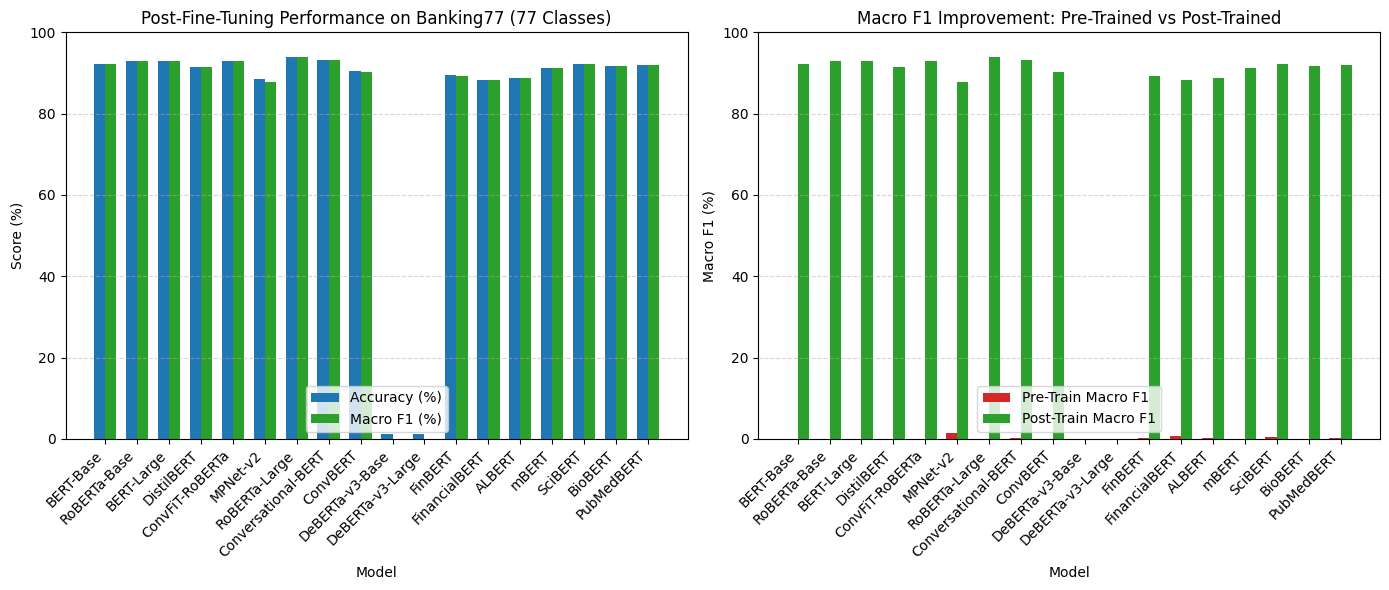

[VISUALIZATION] Saved comparison visualization to: /content/drive/MyDrive/NLP_Checkpoints/BERT_training_Full10k_Awais_Seed42/banking77_bert_full10k_seed42_comparison.png


In [ ]:
# --- 9. Comprehensive Comparison Table & Visualizations ---
benchmark_df = pd.DataFrame(results_records)
print("\n" + "=" * 90)
print(f"FINAL BANKING77 BENCHMARK SUMMARY TABLE (Evaluated on {len(test_texts):,} Test Queries)")
print("=" * 90)
display_cols = [
    "Model Name",
    "Pre-Train Accuracy (%)",
    "Post-Train Accuracy (%)",
    "Accuracy Gain (%)",
    "Pre-Train Macro F1 (%)",
    "Post-Train Macro F1 (%)",
    "Post-Train Weighted F1 (%)",
    "Post-Train Macro Precision (%)",
    "Post-Train Macro Recall (%)",
    "Training Time (min)",
    "Wall Time (s)",
    "Peak VRAM Allocated (GB)"
]
print(benchmark_df[display_cols].to_markdown(index=False) if hasattr(benchmark_df, "to_markdown") else benchmark_df[display_cols])

# Plotting Comparison Charts
plot_save_path = os.path.join(BASE_OUTPUT_DIR, "banking77_bert_full10k_seed42_comparison.png")
plt.figure(figsize=(14, 6))

# Plot 1: Post-Trained Accuracy vs Macro F1
plt.subplot(1, 2, 1)
x = np.arange(len(benchmark_df))
width = 0.35
plt.bar(x - width/2, benchmark_df["Post-Train Accuracy (%)"], width, label="Accuracy (%)", color="#1f77b4")
plt.bar(x + width/2, benchmark_df["Post-Train Macro F1 (%)"], width, label="Macro F1 (%)", color="#2ca02c")
plt.xlabel("Model")
plt.ylabel("Score (%)")
plt.title("Post-Fine-Tuning Performance on Banking77 (77 Classes)")
plt.xticks(x, benchmark_df["Model Name"], rotation=45, ha="right")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Plot 2: Pre-Trained vs Post-Trained Macro F1 Gain
plt.subplot(1, 2, 2)
plt.bar(x - width/2, benchmark_df["Pre-Train Macro F1 (%)"], width, label="Pre-Train Macro F1", color="#d62728")
plt.bar(x + width/2, benchmark_df["Post-Train Macro F1 (%)"], width, label="Post-Train Macro F1", color="#2ca02c")
plt.xlabel("Model")
plt.ylabel("Macro F1 (%)")
plt.title("Macro F1 Improvement: Pre-Trained vs Post-Trained")
plt.xticks(x, benchmark_df["Model Name"], rotation=45, ha="right")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(plot_save_path, dpi=300)
plt.show()
print(f"[VISUALIZATION] Saved comparison visualization to: {plot_save_path}")

In [ ]:
# --- 10. Interactive Prediction Function ---
def load_and_predict(query, model_save_name, top_k=3):
    """
    Loads a saved fine-tuned model checkpoint from its directory and predicts intent.
    """
    model_dir = os.path.join(BASE_OUTPUT_DIR, model_save_name)
    if not os.path.exists(model_dir):
        print(f"[ERROR] Model directory '{model_dir}' not found. Please train the model first.")
        return

    print(f"[LOADING] Loading fine-tuned checkpoint from: {model_dir}...")
    saved_tokenizer = AutoTokenizer.from_pretrained(model_dir)
    saved_model = AutoModelForSequenceClassification.from_pretrained(model_dir).to(device)
    saved_model.eval()

    inputs = saved_tokenizer(query, return_tensors="pt", truncation=True, max_length=MAX_SEQ_LENGTH, padding=True)
    inputs = sanitize_batch_for_model(inputs, saved_model, device)

    with torch.no_grad():
        outputs = saved_model(**inputs)
        probs = torch.softmax(outputs.logits, dim=-1).squeeze(0)
        top_probs, top_indices = torch.topk(probs, k=top_k)

    print(f'\nInput Query: "{query}"')
    print(f"Top {top_k} Predicted Intents:")
    for rank, (idx, prob) in enumerate(zip(top_indices.tolist(), top_probs.tolist()), 1):
        print(f"   {rank}. {id2label[idx]:<35} (Confidence: {prob*100:.2f}%)")

    del saved_model, saved_tokenizer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Example usage:
# load_and_predict("Can I transfer money directly using Apple Pay?", "FinBERT")
